# Notebook 01: Multi-Lingual Corpus Acquisition, Taxonomy & Entropy Audit

## 1. Corpus Balance Formulation
Let $\mathcal{C} = \{d_1, \dots, d_N\}$ be the article catalog spanning categories $\mathcal{K} = \{\text{AI}, \text{Sports}, \text{History}\}$.
Category balance is quantified by normalized Shannon entropy:
$$H(\mathcal{K}) = -\sum_{k \in \mathcal{K}} P(k) \log_2 P(k), \qquad H_{\text{norm}} = \frac{H(\mathcal{K})}{\log_2 |\mathcal{K}|} \in [0, 1]$$
where $H_{\text{norm}} = 1.0$ denotes exact domain balance without majority-class dominance.

In [1]:
import os, sys, json, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Resolve repository root deterministically from ml/notebooks/
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

DATA_DIR = os.path.join(REPO_ROOT, "ml", "data", "processed")
ARTIFACTS_DIR = os.path.join(REPO_ROOT, "ml", "artifacts")
VIZ_DIR = os.path.join(REPO_ROOT, "ml", "visualizations")
plt.rcParams["figure.dpi"] = 110
with open(os.path.join(DATA_DIR, "articles.json"), "r", encoding="utf-8") as f:
    articles = json.load(f)

df = pd.DataFrame(articles)
if "language" not in df.columns:
    df["language"] = "en"
df["language"] = df["language"].fillna("en")

cat_counts = df["category"].value_counts()
probs = cat_counts / cat_counts.sum()
entropy = float(-np.sum(probs * np.log2(probs)))
max_entropy = float(np.log2(len(cat_counts)))

print(f"Total processed corpus articles : {len(df):,}")
print(f"Unique subcategories            : {df['subcategory'].nunique() if 'subcategory' in df else 'N/A'}")
print(f"Category Entropy H(K)           : {entropy:.4f} bits (Normalized: {entropy/max_entropy:.4f})")
print("\nCategory x Language Breakdown:")
print(pd.crosstab(df["category"], df["language"], margins=True))

Total processed corpus articles : 4,050
Unique subcategories            : 60
Category Entropy H(K)           : 1.5850 bits (Normalized: 1.0000)

Category x Language Breakdown:
language    en    id   All
category                  
AI        1000   350  1350
History   1000   350  1350
Sports    1000   350  1350
All       3000  1050  4050


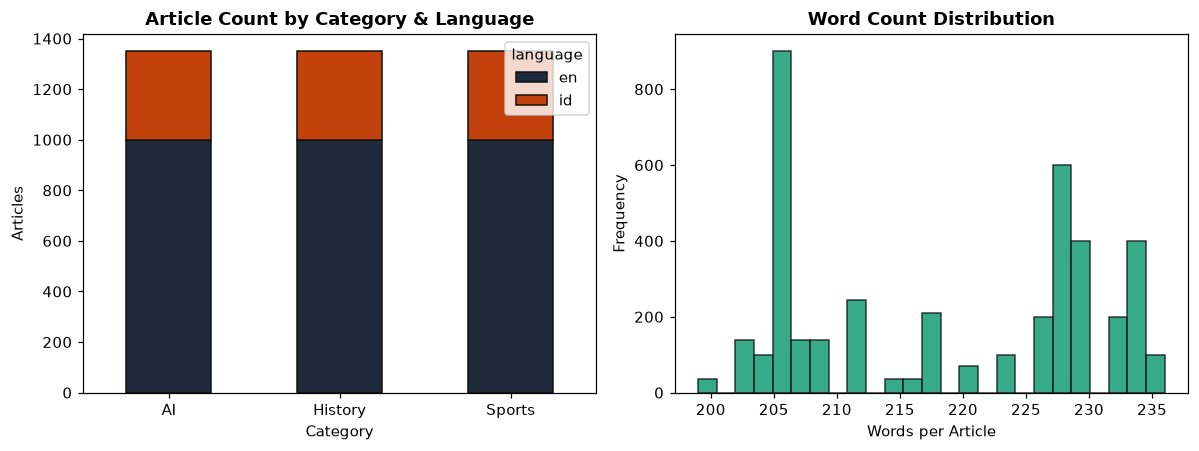

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ct = pd.crosstab(df["category"], df["language"])
ct.plot(kind="bar", stacked=True, ax=axes[0], color=["#1e293b", "#c2410c"], edgecolor="#111110")
axes[0].set_title("Article Count by Category & Language", fontweight="bold")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Articles")
axes[0].tick_params(axis="x", rotation=0)

wc_col = "word_count" if "word_count" in df.columns else ("wordCount" if "wordCount" in df.columns else None)
if wc_col:
    df[wc_col].dropna().plot(kind="hist", bins=25, ax=axes[1], color="#059669", alpha=0.8, edgecolor="#111110")
    axes[1].set_title("Word Count Distribution", fontweight="bold")
    axes[1].set_xlabel("Words per Article")
    axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()